### Variables aleatorias poisson

In [1]:
import math
import random

def generar_poisson(lambd):
    # Paso 1: Generar un número aleatorio u en (0, 1)
    u = random.random()
    
    # Paso 2: Inicializar variables
    i = 0
    p = math.exp(-lambd)
    F = p
    
    # Pasos 3, 4 y 5: Evaluar condición acumulada y actualizar por recurrencia
    while u >= F:
        p = (lambd * p) / (i + 1)
        F = F + p
        i = i + 1
        
    return i

# Parámetros del ejercicio
n = 500
lambd = 10

# Generar los 500 datos
datos_poisson = [generar_poisson(lambd) for _ in range(n)]

# Verificación rápida (la media y varianza muestral deben acercarse a lambda = 10)
media_muestral = sum(datos_poisson) / n
print("Primeros 20 datos:", datos_poisson[:20])
print(f"Media muestral: {media_muestral:.4f}")

Primeros 20 datos: [4, 8, 11, 8, 7, 8, 6, 10, 7, 8, 12, 5, 9, 11, 11, 12, 9, 10, 12, 5]
Media muestral: 10.0320


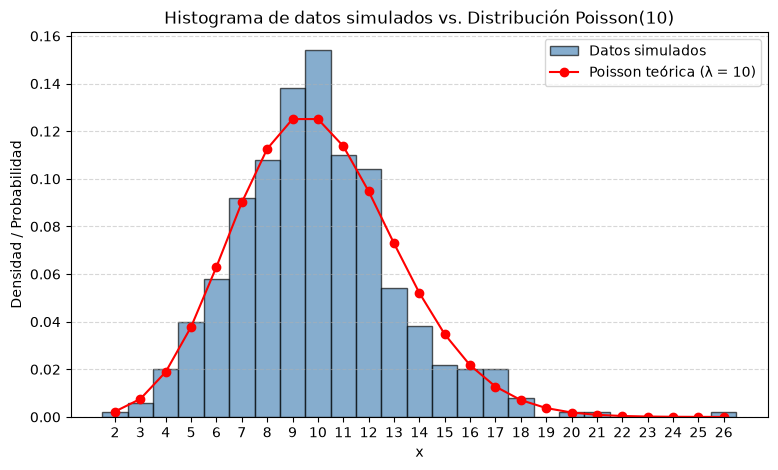

Estadístico Chi-cuadrada: 12.5610
Grados de libertad: 13
Valor p: 0.4823
Decisión (α = 0.05): No se rechaza H0. Los datos siguen una distribución Poisson(10).


In [2]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson, chisquare

def generar_poisson(lambd):
    u = random.random()
    i = 0
    p = math.exp(-lambd)
    F = p
    while u >= F:
        p = (lambd * p) / (i + 1)
        F = F + p
        i = i + 1
    return i

# 1. Generar los 500 datos
n = 500
lambd = 10
datos = [generar_poisson(lambd) for _ in range(n)]

# 2. Histograma vs. Función de Masa de Probabilidad (PMF) teórica
valores_x = np.arange(min(datos), max(datos) + 1)
bins = np.arange(min(datos) - 0.5, max(datos) + 1.5, 1)

plt.figure(figsize=(9, 5))
plt.hist(datos, bins=bins, density=True, alpha=0.65, color='steelblue', edgecolor='black', label='Datos simulados')
plt.plot(valores_x, poisson.pmf(valores_x, lambd), 'ro-', linewidth=1.5, label=f'Poisson teórica (λ = {lambd})')
plt.title('Histograma de datos simulados vs. Distribución Poisson(10)')
plt.xlabel('x')
plt.ylabel('Densidad / Probabilidad')
plt.xticks(valores_x)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

# 3. Prueba de bondad de ajuste Chi-cuadrada
# Se agrupan las colas (X <= 4 y X >= 17) para garantizar frecuencias esperadas E_i >= 5
obs_izq = sum(x <= 4 for x in datos)
obs_centro = [sum(x == k for x in datos) for k in range(5, 17)]
obs_der = sum(x >= 17 for x in datos)
f_obs = np.array([obs_izq] + obs_centro + [obs_der])

p_izq = poisson.cdf(4, lambd)
p_centro = [poisson.pmf(k, lambd) for k in range(5, 17)]
p_der = poisson.sf(16, lambd)  # P(X >= 17)
f_esp = n * np.array([p_izq] + p_centro + [p_der])

estadistico_chi2, p_valor = chisquare(f_obs=f_obs, f_exp=f_esp)

print(f"Estadístico Chi-cuadrada: {estadistico_chi2:.4f}")
print(f"Grados de libertad: {len(f_obs) - 1}")
print(f"Valor p: {p_valor:.4f}")

if p_valor > 0.05:
    print("Decisión (α = 0.05): No se rechaza H0. Los datos siguen una distribución Poisson(10).")
else:
    print("Decisión (α = 0.05): Se rechaza H0.")

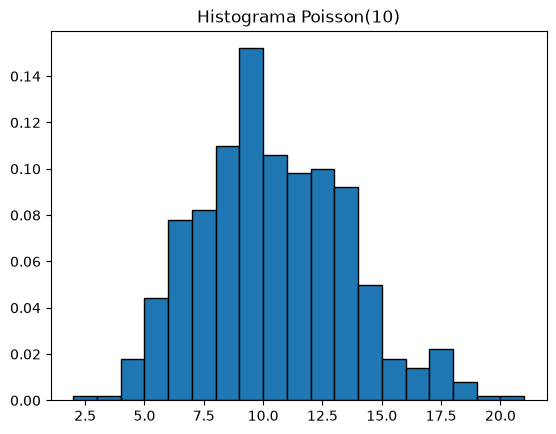

Estadístico D: 0.1219 | p-valor: 0.0000


In [3]:
import math, random
import matplotlib.pyplot as plt
from scipy.stats import kstest, poisson

def gen_poisson(l):
    u, i, p = random.random(), 0, math.exp(-l)
    F = p
    while u >= F:
        p = l * p / (i + 1)
        F += p
        i += 1
    return i

datos = [gen_poisson(10) for _ in range(500)]

# Histograma
plt.hist(datos, bins=range(min(datos), max(datos) + 2), density=True, edgecolor='black')
plt.title('Histograma Poisson(10)')
plt.show()

# Prueba de bondad de ajuste Kolmogorov-Smirnov
stat, p_valor = kstest(datos, poisson.cdf, args=(10,))
print(f"Estadístico D: {stat:.4f} | p-valor: {p_valor:.4f}")

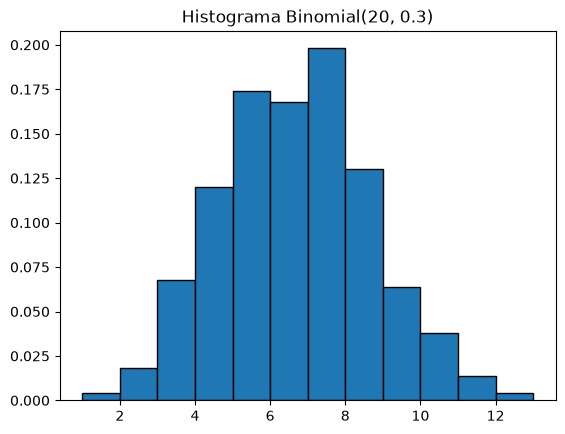

Estadístico D: 0.2240 | p-valor: 0.0000
Primeros 20 datos: [6, 4, 3, 5, 6, 8, 5, 6, 3, 5, 6, 4, 8, 10, 6, 5, 3, 4, 7, 6, 7, 5, 8, 8, 3, 1, 4, 5, 5, 4, 9, 5, 6, 5, 3, 9, 7, 6, 4, 6, 9, 6, 11, 6, 10, 12, 10, 7, 8, 3, 8, 5, 3, 8, 7, 10, 4, 5, 4, 4, 4, 4, 11, 7, 5, 8, 4, 3, 8, 8, 6, 6, 6, 9, 5, 10, 8, 2, 8, 5, 7, 7, 5, 6, 9, 5, 10, 6, 7, 6, 7, 4, 3, 6, 6, 4, 10, 6, 5, 8, 4, 5, 6, 6, 7, 10, 7, 9, 10, 4, 4, 10, 6, 3, 3, 6, 4, 5, 12, 4, 6, 6, 5, 3, 6, 7, 7, 6, 7, 6, 10, 4, 4, 7, 7, 6, 7, 5, 3, 9, 4, 6, 5, 5, 9, 5, 6, 10, 8, 8, 6, 9, 6, 5, 7, 6, 2, 10, 8, 7, 9, 4, 7, 10, 4, 7, 8, 4, 9, 7, 6, 8, 7, 9, 7, 2, 5, 7, 2, 9, 1, 5, 5, 7, 4, 7, 4, 7, 4, 7, 5, 5, 7, 8, 5, 5, 8, 5, 4, 5]


In [ ]:
import random
import matplotlib.pyplot as plt
from scipy.stats import kstest, binom

def gen_binomial(n, p):
    q = 1 - p
    u, i, pr = random.random(), 0, q**n
    F = pr
    while u >= F:
        pr = ((n - i) / (i + 1)) * (p / q) * pr
        F += pr
        i += 1
    return i

datos = [gen_binomial(20, 0.3) for _ in range(500)]

# Histograma
plt.hist(datos, bins=range(min(datos), max(datos) + 2), density=True, edgecolor='black')
plt.title('Histograma Binomial(20, 0.3)')
plt.show()

# Prueba de bondad de ajuste Kolmogorov-Smirnov
stat, p_valor = kstest(datos, binom.cdf, args=(20, 0.3))
print(f"Estadístico D: {stat:.4f} | p-valor: {p_valor:.4f}")
print("Primeros 200 datos:", datos[:200])

Primeras 10 parejas: [(0.43179916380691774, 0.15367681799189437), (0.04419199683427777, 0.3449500927087529), (0.26323227892358714, 0.6501795722323569), (0.8382537371332305, 0.82843370195893), (0.8511791243950413, 0.13757784255037386), (0.10722932716713851, 0.2323191510294279), (0.2160115460286386, 0.04659510599360639), (0.07090255842114046, 0.28759182564451347), (0.6069925818794022, 0.20036834121062752), (0.40531487461398186, 0.40031320583579544)]
Estimación de π: 3.144082


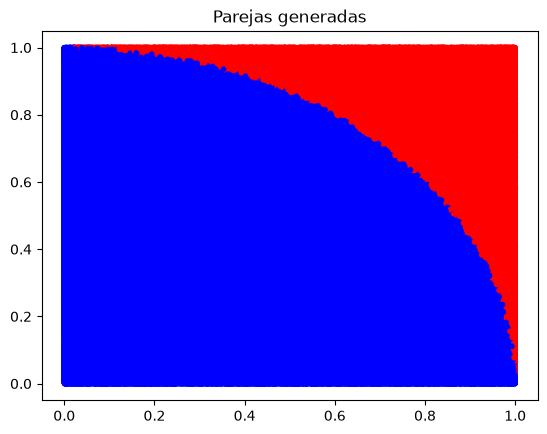

In [18]:
import random
import matplotlib.pyplot as plt

n = 2000000
parejas = [(random.random(), random.random()) for _ in range(n)]
dentro = [x**2 + y**2 <= 1 for x, y in parejas]

print("Primeras 10 parejas:", parejas[:10])
print(f"Estimación de π: {4 * (sum(dentro) / n)}")

# Gráfica de las parejas generadas
x, y = zip(*parejas)
colores = ['blue' if d else 'red' for d in dentro]
plt.scatter(x, y, c=colores, s=10)
plt.title('Parejas generadas')
plt.show()